# Machine learning zoomcamp midterm project

### The purpose of this project is to do inferences about the Club Atletico Independiente de Avellaneda and if the team would win according it's adversary and if it is playing as local or visitor.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df=pd.read_csv("data/results.csv")
df.columns=df.columns.str.lower().str.replace(" ","_")
df.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id
0,0,Nacional 1976 - Grupo C,1,All Boys,2,0,Aldosivi,0
1,1,Nacional 1976 - Grupo C,0,Aldosivi,4,0,All Boys,1
2,2,Superliga 2019/20 - Fecha 2,0,Aldosivi,0,0,Argentinos,7
3,3,Superliga 2018/19 - Fecha 15,7,Argentinos,1,2,Aldosivi,0
4,4,Torneo 2016 - Fecha 2,0,Aldosivi,3,2,Argentinos,7


In [14]:
df.columns

Index(['unnamed:_0', 'date_name', 'local_team_id', 'local_team',
       'local_result', 'visitor_result', 'visitor_team', 'visitor_team_id'],
      dtype='str')

In [15]:
categorical=['date_name','local_team','visitor_team']
numeric=['local_result','visitor_result']

## EDA

In [16]:
#primero filtramos partidos de independiente
df_independiente=df[(df['local_team']=='Independiente') | (df['visitor_team']=='Independiente')]
df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56


In [18]:
if (df_independiente.isna().sum().sum() == 0):
    print('No contiene elementos nulos')
else:
    print(df_independiente.isna().sum())

No contiene elementos nulos


In [19]:
# extraer el año de la columna date_name, usamos una funcion
def extraer_año(tournament_name):
    import re
    # Buscar cualquier secuencia de cuatro dígitos en el nombre del torneo
    coinc = re.search(r'\d{4}', tournament_name)
    if coinc:
        return coinc.group()
    else:
        return None


In [20]:
df_independiente['anio'] = pd.to_numeric(df_independiente['date_name'].apply(extraer_año))
df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013


In [21]:
#partidos por año
df_independiente['anio'].value_counts().reset_index()

,anio,count
0,1977,62
1,1978,60
2,1983,56
3,1980,54
4,1975,54
...,...,...
85,2019,23
86,2013,19
87,1990,19
88,2014,19


In [22]:
#filtramos 2021 por falta de partidos
df_independiente = df_independiente[df_independiente['anio'] <= 2019]
df_independiente['anio'].value_counts().reset_index()

,anio,count
0,1977,62
1,1978,60
2,1983,56
3,1980,54
4,1975,54
...,...,...
84,2018,25
85,2019,23
86,2013,19
87,1990,19


In [23]:
df_independiente['condicion_independiente'] = np.where(
    df_independiente['local_team'] == 'Independiente', 
    'Local', 
    'Visitante'
)

df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio,condicion_independiente
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019,Visitante
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018,Local
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016,Visitante
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015,Visitante
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013,Visitante


In [24]:
#Agregamos columna de empate o victoria (local o visitante)
condiciones=[df_independiente['local_result']<df_independiente['visitor_result'],df_independiente['local_result']==df_independiente['visitor_result'],df_independiente['local_result']>df_independiente['visitor_result']]
resultados=['Victoria visitante','Empate','Victoria local']
condiciones_independiente=[(df_independiente['visitor_team']=='Independiente') & (df_independiente['local_result']==df_independiente['visitor_result']),(df_independiente['local_team']=='Independiente') & (df_independiente['local_result']==df_independiente['visitor_result']),(df_independiente['local_team']=='Independiente') & (df_independiente['local_result']>df_independiente['visitor_result']),(df_independiente['local_team']=='Independiente') & (df_independiente['local_result']<df_independiente['visitor_result']),(df_independiente['visitor_team']=='Independiente') & (df_independiente['visitor_result']>df_independiente['local_result']),(df_independiente['visitor_team']=='Independiente') & (df_independiente['visitor_result']<df_independiente['local_result'])]
resultados_independiente=['Empate visitante','Empate local','Victoria de local','Derrota de local','Victoria de visitante','Derrota de visitante']
df_independiente['victoria']=np.select(condiciones,resultados,default="NS")
df_independiente['victoria_independiente']=np.select(condiciones_independiente,resultados_independiente,default="Empate")

df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio,condicion_independiente,victoria,victoria_independiente
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019,Visitante,Empate,Empate visitante
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018,Local,Victoria local,Victoria de local
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016,Visitante,Empate,Empate visitante
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015,Visitante,Victoria local,Derrota de visitante
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013,Visitante,Victoria local,Derrota de visitante


In [25]:
#Agregamos goles totales y diferencia de goles
#primero filtramos partidos de independiente
df_independiente['gol_de_independiente'] = np.where(
    df_independiente['local_team'] == 'Independiente', 
    df_independiente['local_result'],   # Si Independiente es local, toma los goles locales
    df_independiente['visitor_result']  # Si no, toma los goles de visitante
)
df_independiente['gol_contra_independiente'] = np.where(
    df_independiente['local_team'] != 'Independiente', 
    df_independiente['local_result'],   # Si Independiente es local, toma los goles locales
    df_independiente['visitor_result']  # Si no, toma los goles de visitante
)
df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio,condicion_independiente,victoria,victoria_independiente,gol_de_independiente,gol_contra_independiente
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019,Visitante,Empate,Empate visitante,0,0
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018,Local,Victoria local,Victoria de local,2,0
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016,Visitante,Empate,Empate visitante,0,0
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015,Visitante,Victoria local,Derrota de visitante,0,1
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013,Visitante,Victoria local,Derrota de visitante,0,2


In [26]:
df_independiente.describe().T

,count,mean,std,min,25%,50%,75%,max
unnamed:_0,3258.0,18784.033149,7387.467137,82.0,13507.25,23632.5,24448.75,25263.0
local_team_id,3258.0,54.370473,19.453035,0.0,56.00,56.0,63.00,94.0
local_result,3258.0,1.638428,1.428693,0.0,1.00,1.0,2.00,10.0
visitor_result,3258.0,1.228975,1.191154,0.0,0.00,1.0,2.00,11.0
visitor_team_id,3258.0,54.255678,19.549297,0.0,56.00,56.0,63.00,94.0
anio,3258.0,1976.002149,24.419455,1931.0,1956.00,1977.0,1996.00,2019.0
gol_de_independiente,3258.0,1.640884,1.468096,0.0,1.00,1.0,2.00,11.0
gol_contra_independiente,3258.0,1.226519,1.141350,0.0,0.00,1.0,2.00,8.0


In [27]:
df_independiente['target'] = (
        df_independiente['victoria_independiente'].isin(['Victoria de local', 'Victoria de visitante'])
).astype(int)

print("Distribución de la variable objetivo (target):")
print(df_independiente['target'].value_counts(normalize=True))


Distribución de la variable objetivo (target):
target
0    0.56108
1    0.43892
Name: proportion, dtype: float64


                         Mutual Information
rival                              0.027792
condicion_independiente            0.017657


<positron-console-cell-28>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



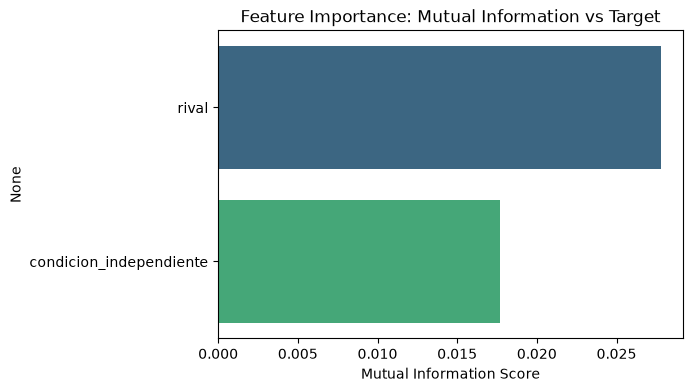

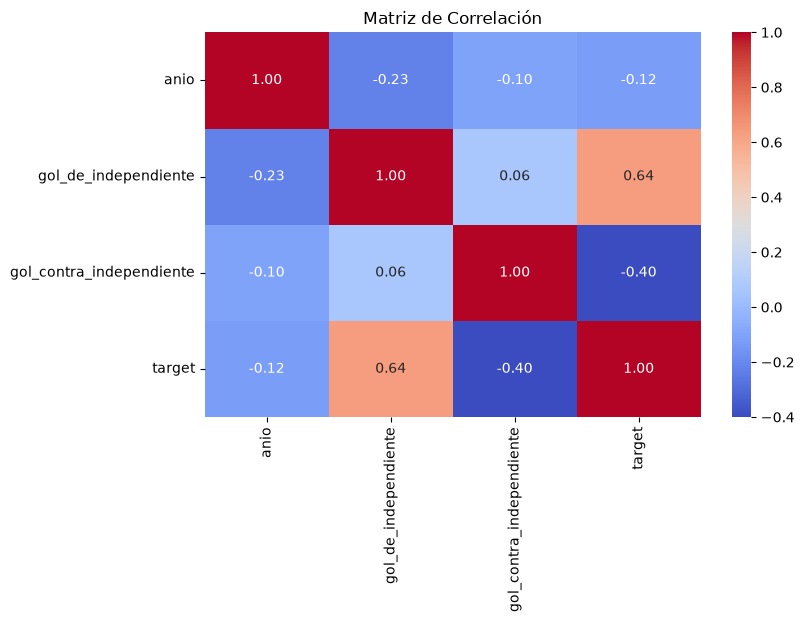

In [28]:
from sklearn.metrics import mutual_info_score

    # Identificar al rival de Independiente en cada partido
df_independiente['rival'] = np.where(
        df_independiente['local_team'] == 'Independiente',
        df_independiente['visitor_team'],
        df_independiente['local_team']
    )

def calculate_mi(series):
        return mutual_info_score(series, df_independiente['target'])

cat_features = ['rival', 'condicion_independiente']
df_mi = df_independiente[cat_features].apply(calculate_mi).sort_values(ascending=False).to_frame(name='Mutual Information')

print(df_mi)

plt.figure(figsize=(6, 4))
sns.barplot(x=df_mi['Mutual Information'], y=df_mi.index, palette='viridis')
plt.title('Feature Importance: Mutual Information vs Target')
plt.xlabel('Mutual Information Score')
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(df_independiente[['anio', 'gol_de_independiente', 'gol_contra_independiente', 'target']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlación')
plt.show()

In [29]:
#media, mediana y moda de goles y diferencia de goles
print("La media de goles de Independiente es: ", df_independiente['gol_de_independiente'].mean())
print("La mediana de goles de Independiente es: ", df_independiente['gol_de_independiente'].median())
print("La moda de goles de Independiente es: ", df_independiente['gol_de_independiente'].mode())

print("La media de goles contra Independiente es: ", df_independiente['gol_contra_independiente'].mean())
print("La mediana de goles contra Independiente es: ", df_independiente['gol_contra_independiente'].median())
print("La moda de goles contra Independiente es: ", df_independiente['gol_contra_independiente'].mode())

La media de goles de Independiente es:  1.6408839779005524
La mediana de goles de Independiente es:  1.0
La moda de goles de Independiente es:  0    1
Name: gol_de_independiente, dtype: int64
La media de goles contra Independiente es:  1.2265193370165746
La mediana de goles contra Independiente es:  1.0
La moda de goles contra Independiente es:  0    1
Name: gol_contra_independiente, dtype: int64


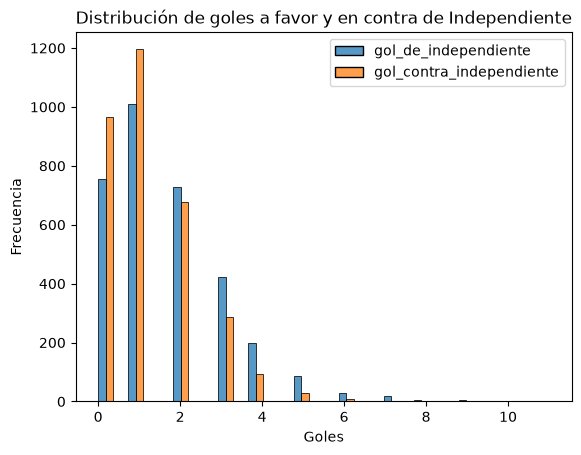

In [30]:
sns.histplot(data=df_independiente[['gol_de_independiente', 'gol_contra_independiente']],multiple='dodge',bins=30)
plt.title("Distribución de goles a favor y en contra de Independiente")
plt.xlabel("Goles")
plt.ylabel("Frecuencia")
plt.show()

<Axes: title={'center': 'Resultados del CAI'}>

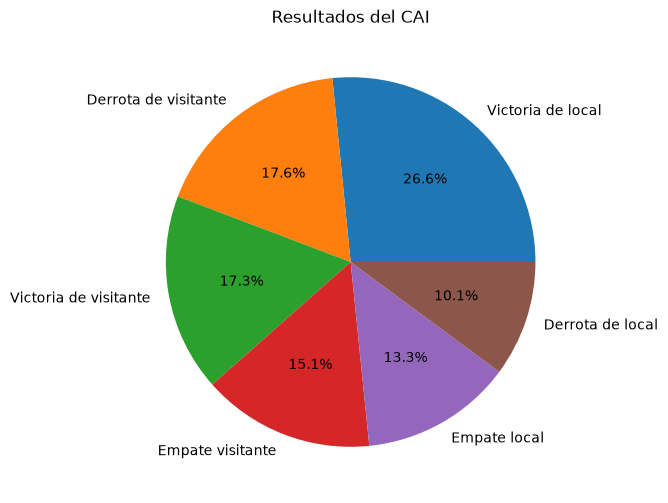

In [31]:
df_independiente['victoria_independiente'].value_counts().plot(kind='pie', title='Resultados del CAI',autopct='%1.1f%%', figsize=(6, 6))

In [32]:
goles_año=df_independiente.groupby(['anio'])[['gol_de_independiente', 'gol_contra_independiente']].mean().reset_index()
goles_graph = goles_año.melt(
    id_vars=['anio'], 
    value_vars=['gol_de_independiente', 'gol_contra_independiente'],
    var_name='tipo_de_gol',
    value_name='cantidad_goles'
)

In [33]:
df['anio'] = pd.to_numeric(df['date_name'].apply(extraer_año))
df['goles_totales']=df['local_result']+df['visitor_result']
df['goles_por_equipo'] = (df['local_result'] + df['visitor_result']) / 2
df = df[df['anio'] <= 2019]

goles_año_total=df.groupby(['anio'])[['goles_por_equipo']].mean().reset_index()
goles_año_total_graph=goles_año_total.melt(id_vars=['anio'],value_vars=['goles_por_equipo'],var_name='goles_por_equipo',value_name='cantidad_goles')

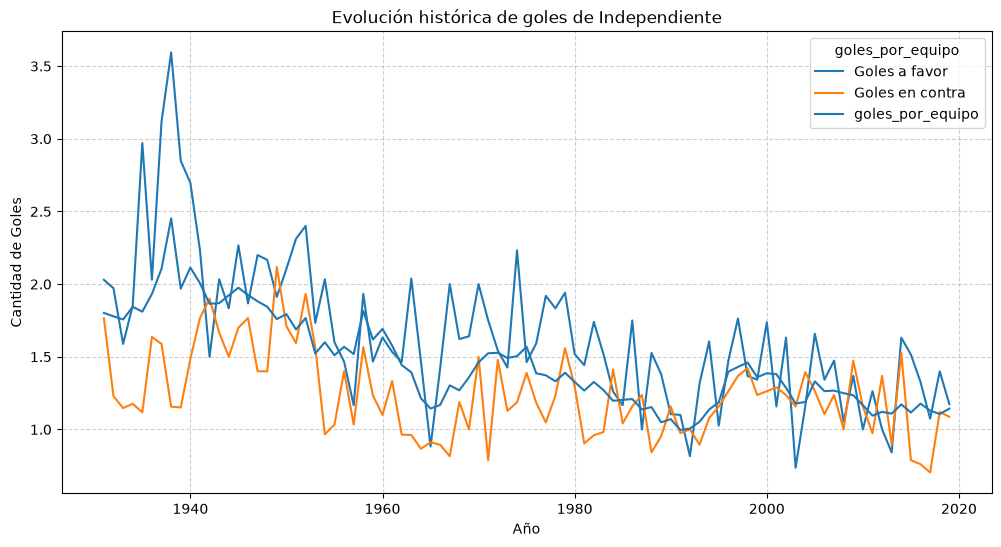

In [34]:
goles_graph['tipo_de_gol'] = goles_graph['tipo_de_gol'].replace({
    'gol_de_independiente': 'Goles a favor',
    'gol_contra_independiente': 'Goles en contra'
})

goles_graph['leyenda'] = goles_graph['tipo_de_gol']

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=goles_graph, 
    x='anio', 
    y='cantidad_goles', 
    hue='leyenda')
sns.lineplot(
    data=goles_año_total_graph, 
    x='anio', 
    y='cantidad_goles', 
    hue='goles_por_equipo')

plt.title('Evolución histórica de goles de Independiente')
plt.xlabel('Año')
plt.ylabel('Cantidad de Goles')
plt.grid(True, linestyle='--', alpha=0.6) # Una grilla suave de fondo

plt.show()

In [35]:
ganados=df_independiente.groupby(['anio','victoria_independiente'])[['victoria_independiente']].value_counts().reset_index()

In [36]:
ganados=df_independiente.groupby(['anio','victoria_independiente'])[['victoria_independiente']].value_counts().reset_index()
ganados_graph = ganados.melt(
    id_vars=['anio', 'victoria_independiente'], # Mantenemos ambas variables para no perder el dato de la victoria
    value_name='cantidad_partidos'
)
ganados_graph = ganados_graph[ganados_graph['victoria_independiente'].isin(['Victoria de local', 'Victoria de visitante'])]

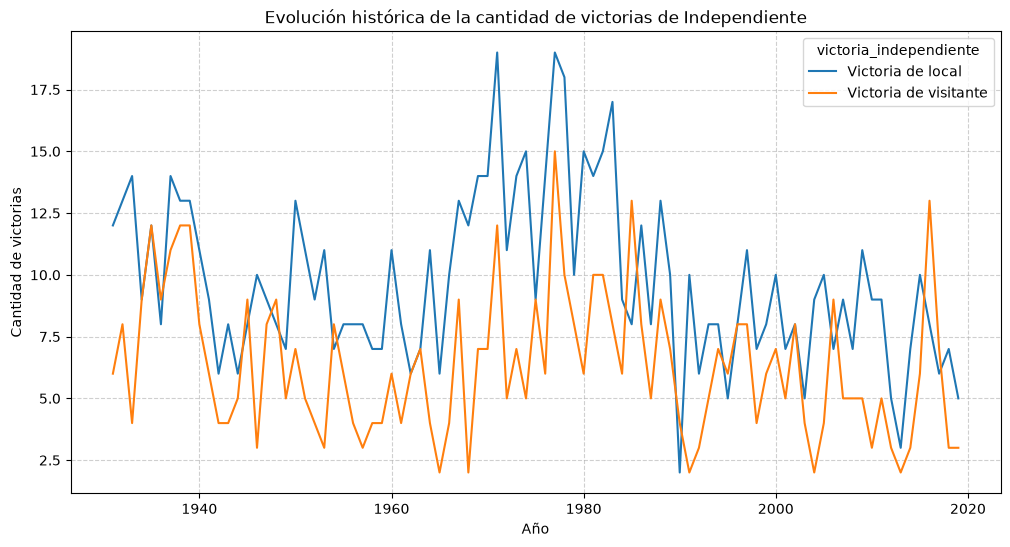

In [37]:
ganados_graph
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=ganados_graph, 
    x='anio', 
    y='cantidad_partidos', 
    hue='victoria_independiente')

plt.title('Evolución histórica de la cantidad de victorias de Independiente')
plt.xlabel('Año')
plt.ylabel('Cantidad de victorias')
plt.grid(True, linestyle='--', alpha=0.6) # Una grilla suave de fondo

plt.show()

## Model training

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score,
        confusion_matrix,
        classification_report
    )

In [40]:
features=['rival','condicion_independiente','anio']
target='target'

In [41]:
#train, val, test
df_train_full, df_test = train_test_split(df_independiente, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=42)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values


In [42]:
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')
test_dicts = df_test[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

In [57]:
#modelo lineal
for c in [0.001, 0.01, 0.1, 1.0, 10.0]:
        lr = LogisticRegression(C=c, max_iter=1000, random_state=42)
        lr.fit(X_train, y_train)
        y_pred = lr.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        print(f"Logistic Regression | C={c:6} | Val AUC: {auc:.4f}")

Logistic Regression | C= 0.001 | Val AUC: 0.5758
Logistic Regression | C=  0.01 | Val AUC: 0.6216
Logistic Regression | C=   0.1 | Val AUC: 0.6382


C:\Users\rafah\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression | C=   1.0 | Val AUC: 0.6413


C:\Users\rafah\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression | C=  10.0 | Val AUC: 0.6378


C:\Users\rafah\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [60]:
lr = LogisticRegression(C=1, max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr=lr.predict_proba(X_val)[:, 1]

C:\Users\rafah\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
#decision tree
for depth in [3, 5, 7, 10]:
        for s in [5, 10, 20]:
            dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s, random_state=42)
            dt.fit(X_train, y_train)
            y_pred = dt.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)
            print(f"Decision Tree | depth={depth:2} | min_samples_leaf={s:2} | Val AUC: {auc:.4f}")


Decision Tree | depth= 3 | min_samples_leaf= 5 | Val AUC: 0.6108
Decision Tree | depth= 3 | min_samples_leaf=10 | Val AUC: 0.6108
Decision Tree | depth= 3 | min_samples_leaf=20 | Val AUC: 0.6177
Decision Tree | depth= 5 | min_samples_leaf= 5 | Val AUC: 0.6127
Decision Tree | depth= 5 | min_samples_leaf=10 | Val AUC: 0.6154
Decision Tree | depth= 5 | min_samples_leaf=20 | Val AUC: 0.6187
Decision Tree | depth= 7 | min_samples_leaf= 5 | Val AUC: 0.6097
Decision Tree | depth= 7 | min_samples_leaf=10 | Val AUC: 0.6193
Decision Tree | depth= 7 | min_samples_leaf=20 | Val AUC: 0.6017
Decision Tree | depth=10 | min_samples_leaf= 5 | Val AUC: 0.5895
Decision Tree | depth=10 | min_samples_leaf=10 | Val AUC: 0.5994
Decision Tree | depth=10 | min_samples_leaf=20 | Val AUC: 0.5930


In [61]:
dt = DecisionTreeClassifier(max_depth=7, min_samples_leaf=10, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict_proba(X_val)[:, 1]

In [ ]:
#random forest
for n in [50, 100, 150]:
        for depth in [5, 10]:
            rf = RandomForestClassifier(n_estimators=n, max_depth=depth, min_samples_leaf=5, random_state=42, n_jobs=-1)
            rf.fit(X_train, y_train)
            y_pred = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)
            print(f"Random Forest | n_estimators={n:3} | max_depth={depth:2} | Val AUC: {auc:.4f}")


Random Forest | n_estimators= 50 | max_depth= 5 | Val AUC: 0.6334
Random Forest | n_estimators= 50 | max_depth=10 | Val AUC: 0.6222
Random Forest | n_estimators=100 | max_depth= 5 | Val AUC: 0.6342
Random Forest | n_estimators=100 | max_depth=10 | Val AUC: 0.6294
Random Forest | n_estimators=150 | max_depth= 5 | Val AUC: 0.6342
Random Forest | n_estimators=150 | max_depth=10 | Val AUC: 0.6280


In [62]:
rf = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict_proba(X_val)[:, 1]

In [ ]:
#xgboost
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=list(dv.get_feature_names_out()))
dval = xgb.DMatrix(X_val, label=y_val, feature_names=list(dv.get_feature_names_out()))
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=list(dv.get_feature_names_out()))

for eta in [0.05, 0.1, 0.3]:
        for max_depth in [3, 6]:
            xgb_params = {
                'eta': eta,
                'max_depth': max_depth,
                'objective': 'binary:logistic',
                'eval_metric': 'auc',
                'seed': 42
            }
            model = xgb.train(xgb_params, dtrain, num_boost_round=100)
            y_pred = model.predict(dval)
            auc = roc_auc_score(y_val, y_pred)
            print(f"XGBoost | eta={eta:4} | max_depth={max_depth:2} | Val AUC: {auc:.4f}")


XGBoost | eta=0.05 | max_depth= 3 | Val AUC: 0.6259
XGBoost | eta=0.05 | max_depth= 6 | Val AUC: 0.6137
XGBoost | eta= 0.1 | max_depth= 3 | Val AUC: 0.6179
XGBoost | eta= 0.1 | max_depth= 6 | Val AUC: 0.6027
XGBoost | eta= 0.3 | max_depth= 3 | Val AUC: 0.6066
XGBoost | eta= 0.3 | max_depth= 6 | Val AUC: 0.5830


In [63]:
xgb_params = {
                'eta': 0.05,
                'max_depth': 3,
                'objective': 'binary:logistic',
                'eval_metric': 'auc',
                'seed': 42
            }
model = xgb.train(xgb_params, dtrain, num_boost_round=100)
y_pred_xgb = model.predict(dval)

In [64]:
def evaluar_modelo(y_true, y_pred_prob, threshold=0.5):
        """Calcula todas las métricas clave dado un umbral de decisión."""
        y_pred = (y_pred_prob >= threshold).astype(int)

        metrics = {
            'ROC-AUC': roc_auc_score(y_true, y_pred_prob),
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred, zero_division=0),
            'F1-Score': f1_score(y_true, y_pred, zero_division=0)
        }
        return metrics

In [65]:
modelos = {
        'Logistic Regression': y_pred_lr,
        'Decision Tree': y_pred_dt,
        'Random Forest': y_pred_rf,
        'XGBoost': y_pred_xgb
    }

resultados = []
for nombre, preds in modelos.items():
        m = evaluar_modelo(y_val, preds, threshold=0.5)
        m['Modelo'] = nombre
        resultados.append(m)

df_comparativa = pd.DataFrame(resultados).set_index('Modelo')
print(df_comparativa.round(4))


                     ROC-AUC  Accuracy  Precision  Recall  F1-Score
Modelo                                                             
Logistic Regression   0.6413    0.6043     0.5911  0.4068    0.4819
Decision Tree         0.6193    0.5859     0.5604  0.3932    0.4622
Random Forest         0.6342    0.5874     0.5793  0.3220    0.4139
XGBoost               0.6259    0.5828     0.5567  0.3831    0.4538


In [67]:
#gana el modelo de regresion logistica
y_pred_best=y_pred_lr

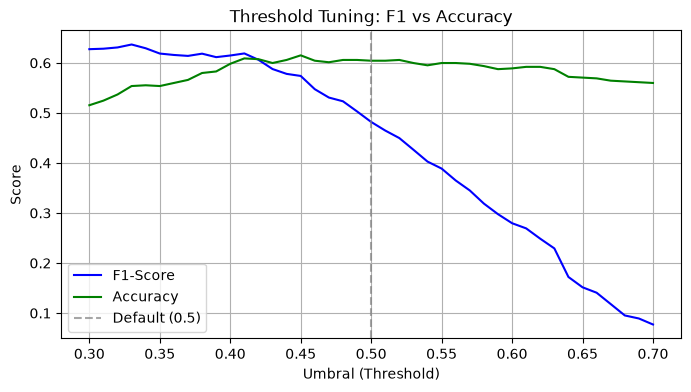

In [68]:
thresholds = np.linspace(0.3, 0.7, 41)
scores = []

for t in thresholds:
        f1 = f1_score(y_val, (y_pred_best >= t).astype(int), zero_division=0)
        acc = accuracy_score(y_val, (y_pred_best >= t).astype(int))
        scores.append({'threshold': t, 'f1': f1, 'accuracy': acc})

df_scores = pd.DataFrame(scores)

plt.figure(figsize=(8, 4))
plt.plot(df_scores['threshold'], df_scores['f1'], label='F1-Score', color='blue')
plt.plot(df_scores['threshold'], df_scores['accuracy'], label='Accuracy', color='green')
plt.axvline(x=0.5, color='gray', linestyle='--', alpha=0.7, label='Default (0.5)')
plt.title('Threshold Tuning: F1 vs Accuracy')
plt.xlabel('Umbral (Threshold)')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()


In [73]:
#metricas optimizadas con threshold
metricas_optimizadas = evaluar_modelo(y_val, y_pred_best, threshold=0.41)

print("Métricas en Validación con Umbral 0.41:")
for k, v in metricas_optimizadas.items():
        print(f"  {k}: {v:.4f}")


Métricas en Validación con Umbral 0.41:
  ROC-AUC: 0.6413
  Accuracy: 0.6089
  Precision: 0.5535
  Recall: 0.7017
  F1-Score: 0.6188


In [74]:
#ya uso test
y_test_pred_prob = lr.predict_proba(X_test)[:, 1]

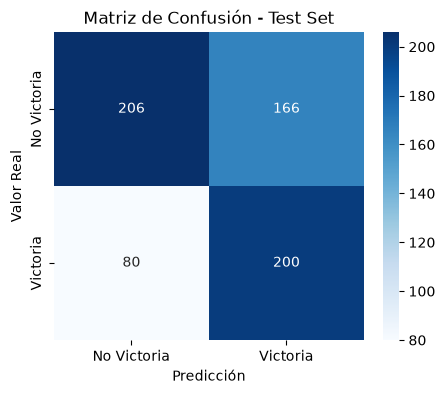


Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

 No Victoria       0.72      0.55      0.63       372
    Victoria       0.55      0.71      0.62       280

    accuracy                           0.62       652
   macro avg       0.63      0.63      0.62       652
weighted avg       0.65      0.62      0.62       652



In [75]:
#matriz de confusión con umbral óptimo
y_test_pred = (y_test_pred_prob >= 0.41).astype(int)

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Victoria', 'Victoria'],
                yticklabels=['No Victoria', 'Victoria'])
plt.title('Matriz de Confusión - Test Set')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_test_pred, target_names=['No Victoria', 'Victoria']))


In [76]:
#modelo final
full_dicts = df_train_full[features].to_dict(orient='records')
X_full = dv.fit_transform(full_dicts)
y_full = df_train_full[target].values

test_dicts = df_test[features].to_dict(orient='records')
X_test = dv.transform(test_dicts)
y_test = df_test[target].values

final_model = LogisticRegression(C=1, max_iter=1000, random_state=42)
final_model.fit(X_full, y_full)

y_test_pred_prob = final_model.predict_proba(X_test)[:, 1]

metricas_test = evaluar_modelo(y_test, y_test_pred_prob, threshold=0.41)
print("Rendimiento Final en el Test Set:")
for k, v in metricas_test.items():
        print(f"  {k}: {v:.4f}")


C:\Users\rafah\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Rendimiento Final en el Test Set:
  ROC-AUC: 0.6881
  Accuracy: 0.6150
  Precision: 0.5391
  Recall: 0.7143
  F1-Score: 0.6144


In [77]:
import pickle

with open('model.bin', 'wb') as f_out:
        pickle.dump((dv, final_model), f_out)                                                                                                                                                   
print("¡Modelo y DictVectorizer guardados exitosamente en 'model.bin'!")

¡Modelo y DictVectorizer guardados exitosamente en 'model.bin'!
